# EVA-CLIP (EVA02-L-14) Zero-shot Benchmark


Mounted at /content/drive
Device: cuda
DATA_ROOT: /content/drive/MyDrive/ArchiStyles-2


open_clip_model.safetensors:   0%|          | 0.00/856M [00:00<?, ?B/s]

Classi: 25 | Esempio: ['Achaemenid', 'American Foursquare', 'American craftsman style', 'Ancient Egyptian', 'Art Deco', 'Art Nouveau', 'Baroque', 'Bauhaus']
temp=0.50 -> Top1=0.6613 MacroF1=0.6595 Top5=0.9395
temp=1.00 -> Top1=0.6613 MacroF1=0.6595 Top5=0.9395
temp=2.00 -> Top1=0.6613 MacroF1=0.6595 Top5=0.9395

Best temperature: 0.5

FINAL -> Top-1=0.6613 | Macro-F1=0.6595 | Top-5=0.9395
Latency: 117.7 ms/img | GPU-h: 0.00

Classification report:

                          precision    recall  f1-score   support

              Achaemenid     0.9697    0.9697    0.9697        33
     American Foursquare     0.3269    0.6071    0.4250        28
American craftsman style     0.7143    0.4000    0.5128        25
        Ancient Egyptian     1.0000    1.0000    1.0000        27
                Art Deco     0.8800    0.6286    0.7333        35
             Art Nouveau     0.7333    0.9167    0.8148        24
                 Baroque     0.6897    0.6452    0.6667        31
                 B

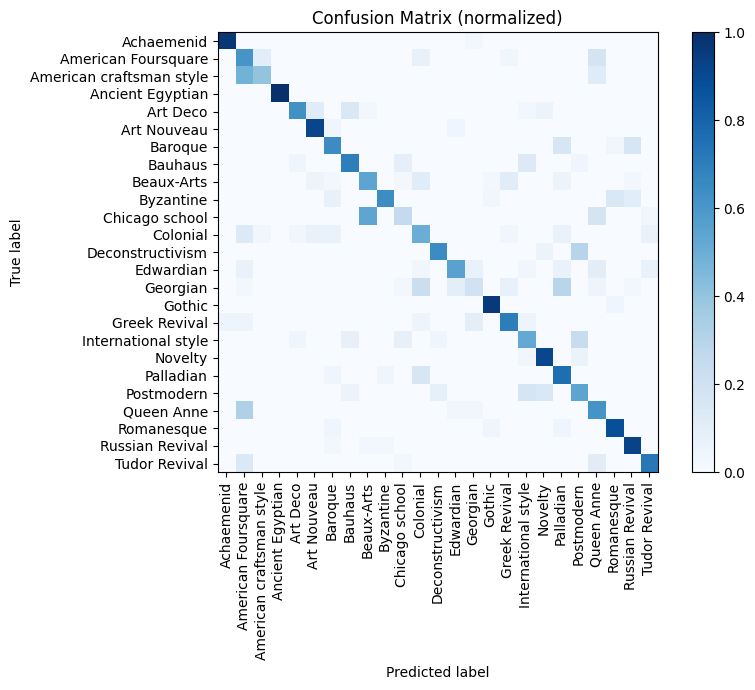

/tmp/ipython-input-1869285598.py:220: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "Timestamp": datetime.utcnow().isoformat(),


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Macro-F1,Top-5 Acc,GPU-h,Latency (ms/img),Effort umano (h),Note,Classes,Batch size
0,2025-08-23T10:55:36.221946,EVA02-L-14-336,merged2b_s6b_b61k,Zero-shot (test),Prompt ensemble + temperature search,0.6613,0.6595,0.9395,0.0,117.7,0.5,"EVA-CLIP L/14 zero-shot, prompt ensemble + tem...",25,32


Salvato CSV: /content/benchmark_results.csv e /content/drive/MyDrive/ArchiStyles-2/benchmark_results.csv


In [3]:
# ============================
# EVA-CLIP (EVA02-L-14) Zero-shot Benchmark
# Coerente con le emtrichevalutate fino ad ora
# ============================

!pip -q install "open_clip_torch>=2.24.0" scikit-learn matplotlib pandas tqdm timm

# --- Imports & Config ---
import os, time, math, json
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import open_clip
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, top_k_accuracy_score
)
import matplotlib.pyplot as plt

# ---- Colab Drive ----
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# ====== CONFIG (MODIFICA QUI) ======
# Path dataset (con cartelle train/ valid/ test)
DATA_ROOT = "/content/drive/MyDrive/ArchiStyles-2"
SPLIT = "test"               # "test" | "valid" | "train"
BATCH_SIZE = 32              # riduci se finisci la VRAM

# Modello EVA-CLIP
MODEL_NAME = "EVA02-L-14-336"    # alternativa ad alta risoluzione: "EVA02-L-14-336"
PRETRAINED = "merged2b_s6b_b61k"  # per 336 usare "merged2b_s6b_b61k"

# Prompt templates
TEMPLATES = [
    "a photo of a {} building",
    "a photograph of {} architecture",
    "an example of {} architecture",
    "a building in {} style",
]
EFFORT_HOURS = 0.5           # stima ore uomo per questa run
NOTES = "EVA-CLIP L/14 zero-shot, prompt ensemble + temperature grid"
TEMP_GRID = [0.5, 1.0, 2.0]  # semplice grid per temperature scaling
# ====================================

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --- Mount/path sanity check (shortcut-safe) ---
import glob
candidates = [
    DATA_ROOT,
    "/content/drive/MyDrive/ArchiStyles-2",
]
candidates += glob.glob("/content/drive/.shortcut-targets-by-id/*/ArchiStyles-2")
DATA_ROOT = next((c for c in candidates if os.path.isdir(c)), DATA_ROOT)
print("DATA_ROOT:", DATA_ROOT)
assert os.path.isdir(os.path.join(DATA_ROOT, SPLIT)), f"Split '{SPLIT}' non trovato in {DATA_ROOT}"

# ======================
# Model & Dataset
# ======================
# open_clip >= 2.24.0 ritorna (model, preprocess_train, preprocess_val)
_pack = open_clip.create_model_and_transforms(model_name=MODEL_NAME, pretrained=PRETRAINED)
if len(_pack) == 3:
    model, preprocess_train, preprocess_val = _pack
    preprocess = preprocess_val
else:  # compat vecchie
    model, _, preprocess = _pack

tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model.to(device).eval()

# Dataset / Dataloader
ds = ImageFolder(os.path.join(DATA_ROOT, SPLIT), transform=preprocess)
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
classnames = ds.classes
num_classes = len(classnames)
print("Classi:", num_classes, "| Esempio:", classnames[:8])

# ======================
# Prompts & Text Embeddings
# ======================
def make_prompts(cname):
    return [t.format(cname) for t in TEMPLATES] + [f"{cname} architecture"]

all_prompts, class_offsets = [], [0]
for cname in classnames:
    ps = make_prompts(cname)
    all_prompts.extend(ps)
    class_offsets.append(len(all_prompts))

tokens = tokenizer(all_prompts).to(device)

with torch.no_grad():
    text_features = model.encode_text(tokens)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

# ======================
# Eval util
# ======================
def evaluate_with_temp(temp):
    y_true, y_pred = [], []
    probs_collector = []
    model_dtype = next(model.parameters()).dtype

    with torch.no_grad():
        for imgs, labels in dl:
            imgs = imgs.to(device, dtype=model_dtype)
            img_features = model.encode_image(imgs)
            img_features = img_features / img_features.norm(dim=-1, keepdim=True)

            # usa logit_scale interno + temperatura custom
            logit_scale = model.logit_scale.exp() * temp
            logits = logit_scale * (img_features @ text_features.T)

            # aggregazione prompt per classe (mean)
            cls_logits = []
            for i in range(num_classes):
                s, e = class_offsets[i], class_offsets[i+1]
                cls_logits.append(logits[:, s:e].mean(dim=1))
            cls_logits = torch.stack(cls_logits, dim=1)

            prob = cls_logits.softmax(dim=-1)
            pred = prob.argmax(dim=-1)

            y_true.extend(labels.tolist())
            y_pred.extend(pred.tolist())
            probs_collector.append(prob.cpu().numpy())

    y_true = np.array(y_true, dtype=int)
    y_pred = np.array(y_pred, dtype=int)
    probs = np.concatenate(probs_collector, axis=0)

    top1 = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    top5 = top_k_accuracy_score(y_true, probs, k=min(5, num_classes), labels=np.arange(num_classes))
    return top1, macro_f1, top5, y_true, y_pred, probs

# ======================
# Temperature search (nota: metodologicamente andrebbe su VALID)
# ======================
best = None
for t in TEMP_GRID:
    top1, macro_f1, top5, _, _, _ = evaluate_with_temp(t)
    print(f"temp={t:.2f} -> Top1={top1:.4f} MacroF1={macro_f1:.4f} Top5={top5:.4f}")
    if best is None or top1 > best[0]:
        best = (top1, macro_f1, top5, t)

best_top1, best_macro_f1, best_top5, best_temp = best
print("\nBest temperature:", best_temp)

# ======================
# Final eval + Latency
# ======================
top1, macro_f1, top5, y_true, y_pred, probs = evaluate_with_temp(best_temp)

def measure_latency(num_batches=20):
    model_dtype = next(model.parameters()).dtype
    # warmup
    it = iter(dl)
    for _ in range(3):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl); imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype)
        with torch.no_grad():
            _ = model.encode_image(imgs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # timed
    times = []
    it = iter(dl)
    for _ in range(min(num_batches, max(1, math.ceil(len(ds)/BATCH_SIZE)))):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl); imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype)
        t0 = time.time()
        with torch.no_grad():
            _ = model.encode_image(imgs)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        times.append((time.time()-t0)/imgs.size(0)*1000.0)
    return float(np.mean(times))

latency_ms = measure_latency()
gpu_hours = 0.0  # zero-shot

print(f"\nFINAL -> Top-1={top1:.4f} | Macro-F1={macro_f1:.4f} | Top-5={top5:.4f}")
print(f"Latency: {latency_ms:.1f} ms/img | GPU-h: {gpu_hours:.2f}")

# ======================
# Report & Confusion Matrix
# ======================
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=classnames, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(9,7))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=classnames,
    normalize="true", cmap="Blues", include_values=False,
    xticks_rotation=90, ax=ax
)
ax.set_title("Confusion Matrix (normalized)")
plt.tight_layout()
plt.show()

# ======================
# Save scorecard row -> benchmark_results.csv
# ======================
row = {
    "Timestamp": datetime.utcnow().isoformat(),
    "Model": MODEL_NAME,
    "Pretrained": PRETRAINED,
    "Scenario": f"Zero-shot ({SPLIT})",
    "Techniques": "Prompt ensemble + temperature search",
    "Top-1 Acc": round(float(top1), 4),
    "Macro-F1": round(float(macro_f1), 4),
    "Top-5 Acc": round(float(top5), 4),
    "GPU-h": gpu_hours,
    "Latency (ms/img)": round(float(latency_ms), 1),
    "Effort umano (h)": float(EFFORT_HOURS),
    "Note": NOTES,
    "Classes": int(len(classnames)),
    "Batch size": int(BATCH_SIZE),
}

df = pd.DataFrame([row])
display(df)

# salva/aggiorna in /content e in DATA_ROOT
local_csv = "/content/benchmark_results.csv"
if os.path.exists(local_csv):
    prev = pd.read_csv(local_csv); out = pd.concat([prev, df], ignore_index=True)
else:
    out = df.copy()
out.to_csv(local_csv, index=False)

drive_csv = os.path.join(DATA_ROOT, "benchmark_results.csv")
try:
    if os.path.exists(drive_csv):
        prev_d = pd.read_csv(drive_csv); out_d = pd.concat([prev_d, df], ignore_index=True)
    else:
        out_d = df.copy()
    out_d.to_csv(drive_csv, index=False)
    print("Salvato CSV:", local_csv, "e", drive_csv)
except Exception as e:
    print("Salvato CSV:", local_csv)
    print("Salvataggio su Drive fallito:", e)
